# IMUSA - Análisis de Errores en Láminas

# Análisis de Errores en Láminas

Las imágenes de las láminas están nombradas de la siguiente forma:
A_B_C_D, donde
A corresponde al estado de la lámina, B para Bueno y M para malo (notar que hasta el momento solo tenemos 1 buena)
B corresponde a uno de los dos tamaños de lámina, P para pequeño y G para grande
C es un número que indica el número de lámina dentro de las 2 categorías anteriores
D es un número que indica el número de imagen de la misma lámina

En este nuevo dataset, como se evidencia en la carpeta "Anotaciones", se estandarizó la captura de la imagen, dejando fijos los parámetros como la distanica focal, luminosidad, etc y que se pueden ver en los exif de 2 imágenes que se adjuntan en dicha carpeta; a su vez, se midió la luminosidad de la zona de captura de las imágenes y se cambió el fondo a uno más oscuro para evitar la saturación.

### Instalación de Librerías

In [16]:
!pip install --upgrade pip
!pip install opencv-python
!pip install matplotlib
!apt-get update
!apt-get install -y libgl1-mesa-glx
!pip install scikit-image

"pip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.
"pip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.
"pip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.
"apt-get" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.
"apt-get" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.
"pip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


In [17]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os
from skimage import morphology

### Cargar Imagen Buena y su representación en Histograma

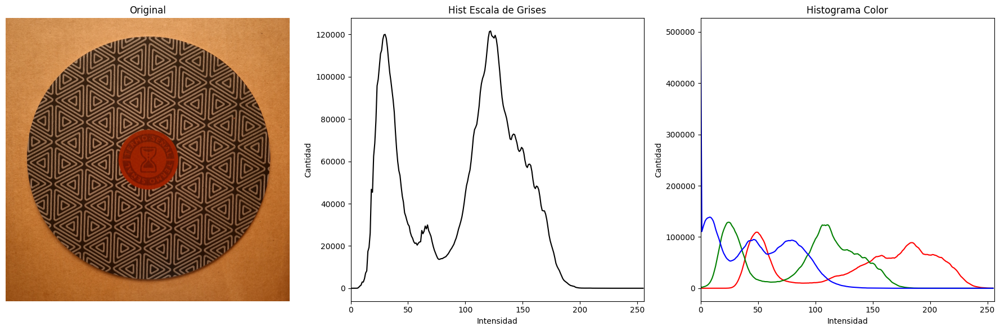

In [18]:
img_buena = cv2.imread('Dataset/B_P_1_1.jpg')

# BGR a RGB
img_rgb = cv2.cvtColor(img_buena, cv2.COLOR_BGR2RGB)

# Grayscale
img_gray = cv2.cvtColor(img_buena, cv2.COLOR_BGR2GRAY)

# Histograma en escala de grises
hist_gray = cv2.calcHist([img_gray], [0], None, [256], [0, 256])

# Histograma de colores RGB
color = ('r', 'g', 'b')
hist_rgb = {}

for i, col in enumerate(color):
    hist_rgb[col] = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])

# Union Imagen - Histograma
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Imagen
axes[0].imshow(img_rgb)
axes[0].set_title('Original')
axes[0].axis('off')

# Histograma grises
axes[1].plot(hist_gray, color='black')
axes[1].set_title('Hist Escala de Grises')
axes[1].set_xlabel('Intensidad')
axes[1].set_ylabel('Cantidad')
axes[1].set_xlim([0, 256])

# Histograma RGB
for col, hist in hist_rgb.items():
    axes[2].plot(hist, color=col)
axes[2].set_title('Histograma Color')
axes[2].set_xlabel('Intensidad')
axes[2].set_ylabel('Cantidad')
axes[2].set_xlim([0, 256])

# Mostrar la figura
plt.tight_layout()
plt.show()

La sección de mayor cantidad o mayor pico representa la cantidad de pixeles que es el fondo "blanco" o claro.

El Pico a la izquierda son los colores grises/negros de la lámina.

### Cargar imágenes malas

Tenemos que recordar que hay varios tipos de errores, los cuales segun su caracteristica se buscan ser identificados.

In [19]:
# Definir la ruta de la carpeta que contiene las imágenes malas
carpeta_imagenes_malas = 'Dataset'

# Crear una lista vacía para almacenar las imágenes
img_malas = []

# Recorrer todos los archivos en la carpeta
for archivo in os.listdir(carpeta_imagenes_malas):
    # Verificar que el archivo sea una imagen (puedes ajustar la condición según tus extensiones)
    if archivo.endswith('.jpg') or archivo.endswith('.png') or archivo.endswith('.jpeg'):
        # Cargar la imagen usando cv2
        ruta_imagen = os.path.join(carpeta_imagenes_malas, archivo)
        imagen = cv2.imread(ruta_imagen)
        # Agregar la imagen a la lista
        img_malas.append(imagen)

# Imprimir la cantidad de imágenes cargadas
print(f"Se han cargado {len(img_malas)} imágenes malas.")


Se han cargado 64 imágenes malas.


### Imágenes con Errores

Escoger índices entre 0 a 55.

- La imagen con index #8 no se le identifican los errores

- La imagen con index #14 no se le identifican los errores

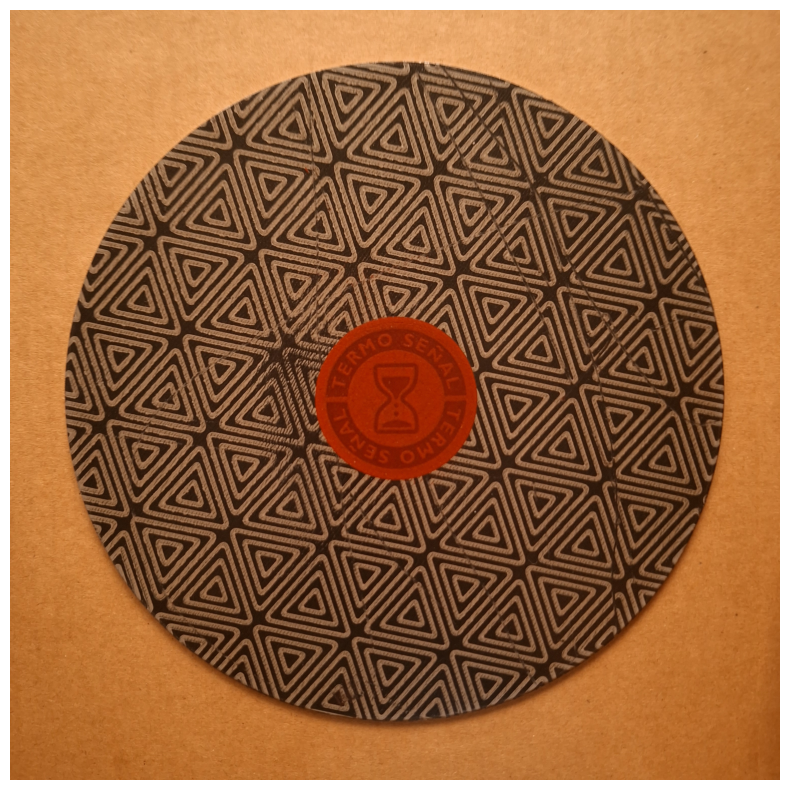

In [20]:
# Escoge el índice de la imagen que deseas analizar (ej. la primera imagen, índice 0)
indx_mala = 36

# Asegurarse de que el índice esté dentro de los límites de la lista
if 0 <= indx_mala < len(img_malas):
    # Obtener la imagen correspondiente
    img_mala = img_malas[indx_mala]
else:
    print(f"Índice {indx_mala} fuera de rango.")

img_rgb = cv2.cvtColor(img_mala, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_mala, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(10, 10))
plt.imshow(img_rgb)
plt.axis('off')
plt.show()

### Representación en LAB

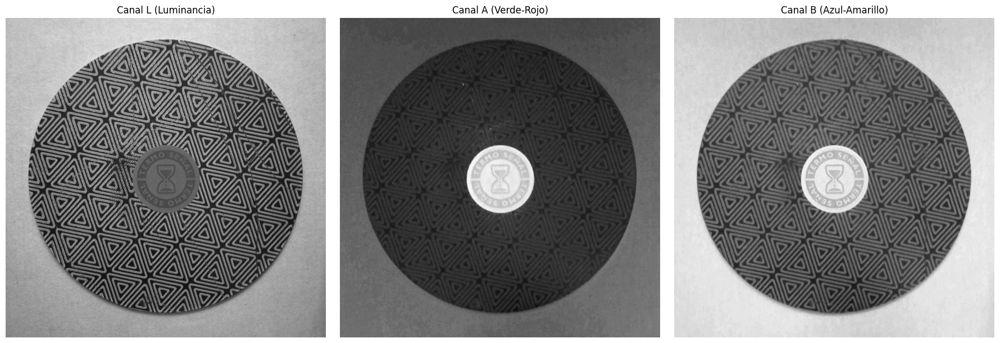

In [21]:
# Convertir la imagen de BGR a LAB
img_lab = cv2.cvtColor(img_mala, cv2.COLOR_BGR2LAB)

# Separar los canales LAB
canal_l, canal_a, canal_b = cv2.split(img_lab)

# Crear una figura para mostrar los canales LAB
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Mostrar el canal L (Luminancia)
axes[0].imshow(canal_l, cmap='gray')
axes[0].set_title('Canal L (Luminancia)')
axes[0].axis('off')

# Mostrar el canal A (Componente verde-rojo)
axes[1].imshow(canal_a, cmap='gray')
axes[1].set_title('Canal A (Verde-Rojo)')
axes[1].axis('off')

# Mostrar el canal B (Componente azul-amarillo)
axes[2].imshow(canal_b, cmap='gray')
axes[2].set_title('Canal B (Azul-Amarillo)')
axes[2].axis('off')

# Mostrar la figura
plt.tight_layout()
plt.show()

En la mayoría de casos para la detección de errores en la etiqueta, el canal más factible es LAB.

# Detección de Textura en la Lámina

### Transformada de Fourier

Calculando la transformada de Fourier aplicando la formula de la magnitud del espectro con el fin de encontrar el dminio de la frecuencia y filtrar los errores dificilmente detectables como por ejemplo los rayones.

Tiempo de ejecución: 6s

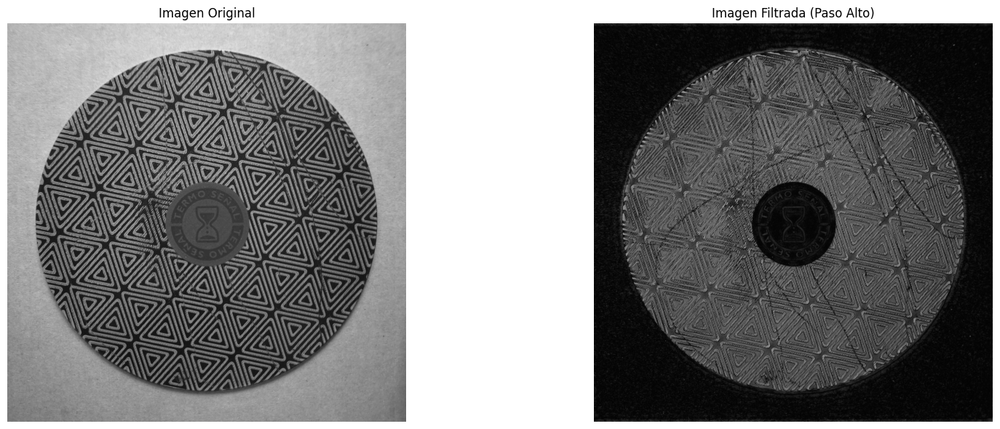

In [22]:
# Aplicar la Transformada de Fourier
f = np.fft.fft2(canal_l)
fshift = np.fft.fftshift(f)  # Desplazar la frecuencia cero al centro del espectro

# Calcular la magnitud del espectro
magnitude_spectrum = np.log(np.abs(fshift) + 1)

# Crear un filtro de paso alto
rows, cols = canal_l.shape
crow, ccol = rows // 2, cols // 2  # Centro del espectro
mask = np.zeros((rows, cols), np.uint8)

# Crear un filtro de paso alto (más intensidad en los bordes)
r = 30  # Radio del filtro
cv2.circle(mask, (ccol, crow), r, 1, thickness=-1)  # Círculo en el centro
high_pass_filter = 1 - mask  # Invertir para paso alto

# Aplicar el filtro en el dominio de la frecuencia
filtered_fshift = fshift * high_pass_filter

# Calcular la magnitud del espectro filtrado
filtered_magnitude_spectrum = np.log(np.abs(filtered_fshift) + 1)

# Convertir el espectro filtrado de nuevo a la imagen
f_ishift = np.fft.ifftshift(filtered_fshift)
img_back = np.fft.ifft2(f_ishift)
img_back = np.abs(img_back)  # Tomar la parte real

# Mostrar resultados
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Imagen original
axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title('Imagen Original')
axes[0].axis('off')

# Imagen filtrada
axes[1].imshow(img_back, cmap='gray')
axes[1].set_title('Imagen Filtrada (Paso Alto)')
axes[1].axis('off')

# Ajustar el espaciado entre los subplots
plt.tight_layout()

# Mostrar la figura
plt.show()

### Operación División

En esta operacion se dividie la imagen filtrada por la imagen origial, ambas normalizadas. Ademas se añade un factor epsilon para evitar la division por 0, abajo podemos ver los resultados. 

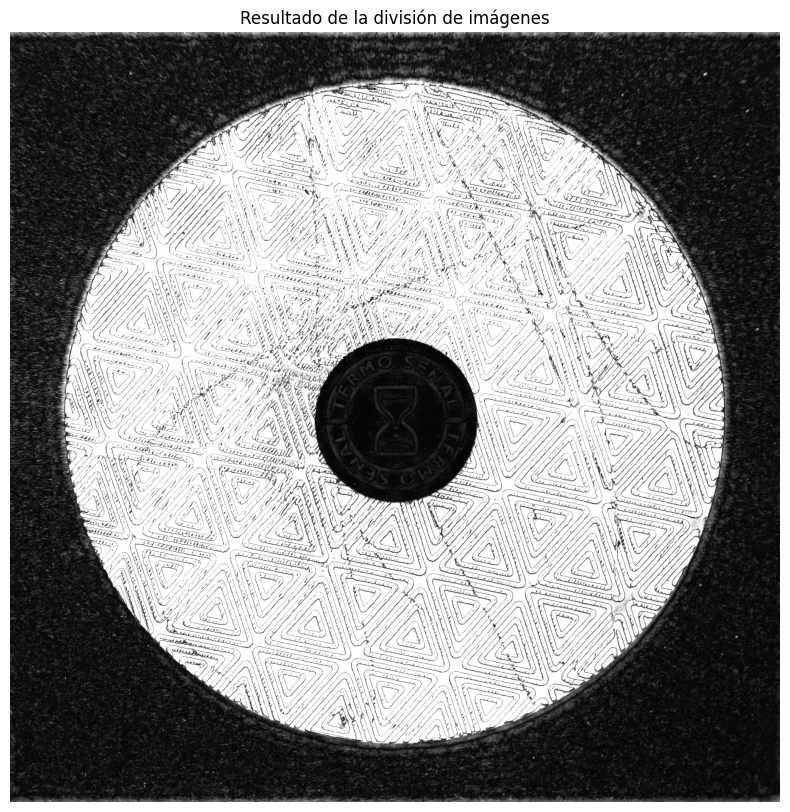

In [23]:
# Normalizar ambas imágenes para la división
img_original_norm = cv2.normalize(canal_a, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)
img_filtered_norm = cv2.normalize(img_back, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)

# Para evitar división por cero, añadimos un pequeño valor (epsilon)
epsilon = 1e-10
img_divided =  0.9*img_filtered_norm / (img_original_norm + epsilon)

# Volver a rango de 0-255 para mostrar la imagen
img_divided_display = cv2.convertScaleAbs(img_divided * 255)

# Mostrar el resultado de la división
plt.figure(figsize=(10, 10))
plt.imshow(img_divided_display, cmap='gray')
plt.title('Resultado de la división de imágenes')
plt.axis('off')
plt.show()


### Umbralización con Otsu

Limpiamos la mayor cantidad de ruido generado por el fondo y la termoimpresión para mejorar la imagen resultante.

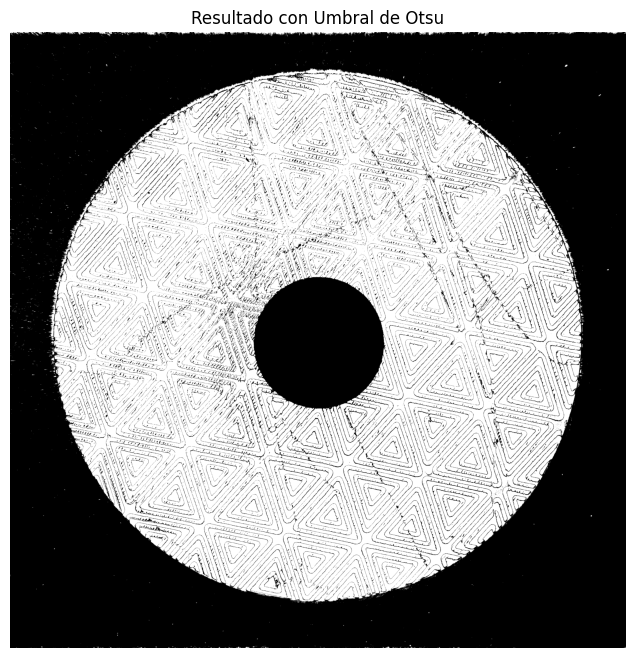

In [24]:
# Normalizar la imagen dividida para asegurar que los valores estén en el rango 0-1
img_divided_norm = cv2.normalize(img_divided_display, None, 0, 1, cv2.NORM_MINMAX)

# Escalar a 0-255 y convertir a tipo CV_8UC1 para aplicar Otsu
img_divided_uint8 = cv2.convertScaleAbs(img_divided_norm, alpha=255)

# Aplicar el umbral de Otsu
_, img_thresh_otsu = cv2.threshold(img_divided_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Mostrar el resultado umbralizado
plt.figure(figsize=(8, 8))
plt.imshow(img_thresh_otsu, cmap='gray')
plt.title('Resultado con Umbral de Otsu')
plt.axis('off')
plt.show()


### Máscara para Segmentación

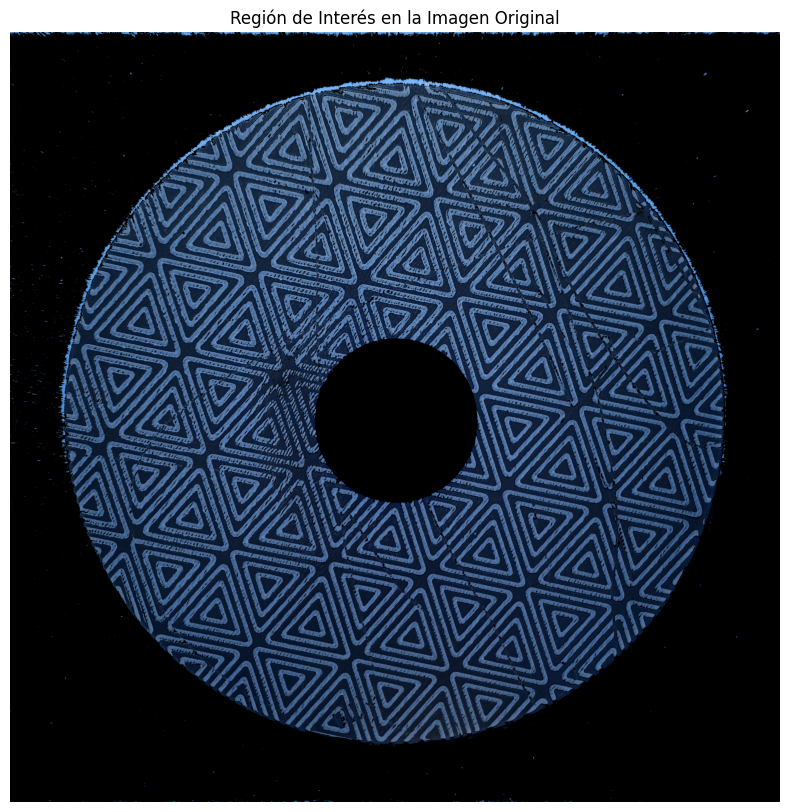

In [25]:
# Crear una máscara binaria a partir de la imagen umbralizada
mascara = cv2.threshold(img_thresh_otsu, 0, 255, cv2.THRESH_BINARY)[1]

# Aplicar la máscara a la imagen original
img_segmentada = cv2.bitwise_and(img_rgb, img_rgb, mask=mascara)

# Mostrar los resultados
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img_segmentada, cv2.COLOR_BGR2RGB))
plt.title("Región de Interés en la Imagen Original")
plt.axis('off')
plt.show()


## Superposición de Máscara

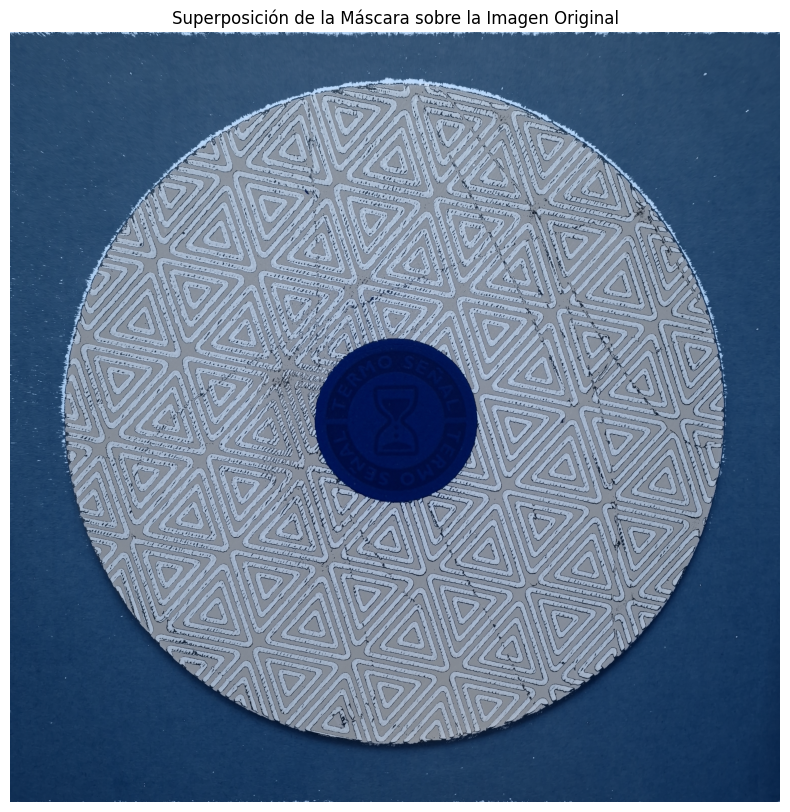

In [26]:
# Convertir la máscara a tres canales para combinarla con la imagen original
mascara_color = cv2.cvtColor(img_thresh_otsu, cv2.COLOR_GRAY2BGR)

# Superponer la máscara sobre la imagen original (con transparencia)
alpha = 0.5  # Transparencia
img_superpuesta = cv2.addWeighted(img_rgb, 1 - alpha, mascara_color, alpha, 0)

# Mostrar la imagen superpuesta
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img_superpuesta, cv2.COLOR_BGR2RGB))
plt.title("Superposición de la Máscara sobre la Imagen Original")
plt.axis('off')
plt.show()


## Feature Matching

Se comienza intentando aplicar la técnica de template matching para la termo señal

### Preprocesamiento

El objetivo es aislar la termo señal de la lámina buena, para esto se encontrará la máscara correspondiente utilizando el canal A del LAB y segmentación por Otsu

C:\Users\jpabl\AppData\Local\Temp\ipykernel_23660\1351460664.py:11: UserWarning: Only one label was provided to `remove_small_objects`. Did you mean to use a boolean array?
  mask_otsu = morphology.remove_small_objects(mask_otsu,200)


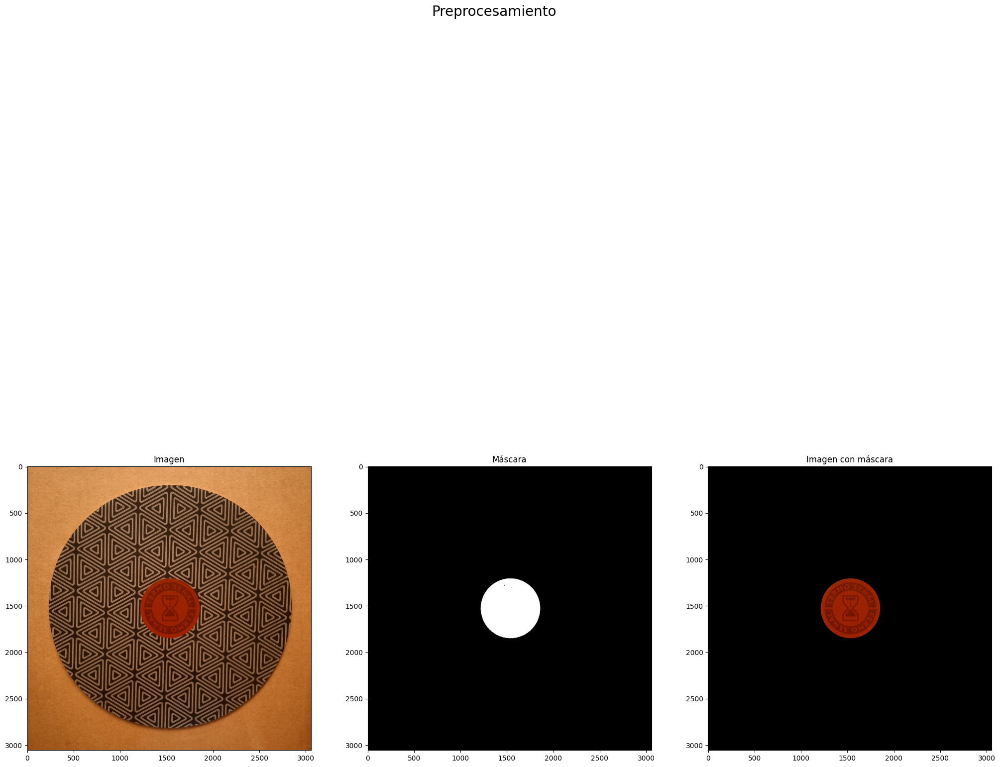

In [27]:
# Función para obtener los canales de LAB
def LAB_div (img):
    LAB_img = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(LAB_img)
    return L, A, B

# Función para obtener imagen con la máscara generada por Otsu
def Otsu (img, img_chan):
    _, mask_otsu = cv2.threshold(img_chan,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    mask_otsu = morphology.label(mask_otsu)
    mask_otsu = morphology.remove_small_objects(mask_otsu,200)
    mask_otsu = (mask_otsu>0).astype(np.uint8)
    #kernel = np.ones((10, 10), np.uint8)
    #mask_otsu = cv2.morphologyEx(mask_otsu, cv2.MORPH_CLOSE, kernel, iterations=7)
    masked_img = cv2.bitwise_and(img, img, mask = mask_otsu)

    return mask_otsu, masked_img

# Función para leer la imagen según el nombre especificado
def Leer_img (folder, nombre):
    image_path = os.path.join(folder, nombre)
    imagen = cv2.imread(image_path)
    imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    return imagen

#Función para obtener e canal A del LAB y la imagen con máscara
def termo_senal (img):
    _, A, _ = LAB_div(img)
    A_mod = cv2.subtract(A,150)
    mask_otsu, masked_img = Otsu(img, A_mod)
    return A, mask_otsu, masked_img

carpeta_imagenes_buenas = 'Dataset'

# Imagen de prueba
img_buena_nom = 'B_P_1_1.jpg'

img_buena = Leer_img(carpeta_imagenes_buenas,img_buena_nom)

chan_A, mask_buena_otsu, img_buena_masked = termo_senal(img_buena)


# Mostrar la máscara y el canal LAB con máscara
hist_fig, hist_arreglo = plt.subplots(1,3, figsize=(25, 25))
hist_fig.suptitle('Preprocesamiento', fontsize=20)

hist_arreglo[0].set_title('Imagen')
hist_arreglo[0].imshow(img_buena, cmap='gray')
hist_arreglo[1].set_title('Máscara')
hist_arreglo[1].imshow(mask_buena_otsu, cmap='gray')
hist_arreglo[2].set_title('Imagen con máscara')
hist_arreglo[2].imshow(img_buena_masked, cmap='gray')

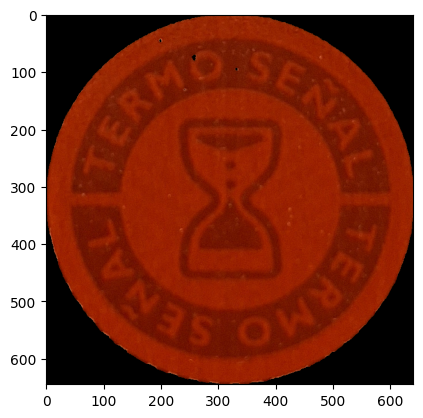

In [ ]:
# Se corta la imagen con la máscaara hallada

coords = np.column_stack(np.where(mask_buena_otsu > 0))

# se  hallan la coordenadas del bounding box
x_min, y_min = coords.min(axis=0)
x_max, y_max = coords.max(axis=0)

cropped_image = img_buena_masked[x_min:x_max, y_min:y_max]

# Se muestra la imagen cortada
plt.imshow(cropped_image, cmap='gray')


Vemos un problema ¡la imagen "buena" no es tan buena! Se procede a aplicar template matching

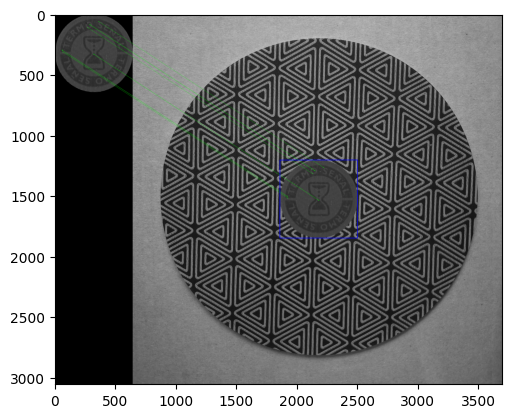

In [ ]:
img1 = cv2.cvtColor(cropped_image, cv2.COLOR_RGB2GRAY)  # Imagen a buscar
img2 = Leer_img(carpeta_imagenes_buenas,'B_P_1_1.jpg')  # Imagen dónde se busca, en escala de grises que es lo común en la técnica de TM
img2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY) 


# Se usa un detector SIFT para identificar las características (funciona mejor que ORB)
sift = cv2.SIFT_create()
# Halla los keypoints y descriptores
kp1, des1 = sift.detectAndCompute(img1,None)
kp2, des2 = sift.detectAndCompute(img2,None)

# crea el objeto BFMatcher
bf = cv2.BFMatcher()
# Hace el match entre los descriptores
matches = bf.match(des1,des2)



# detector ORB (descartado)
'''orb = cv2.ORB_create()
# find the keypoints and descriptors with ORB
kp1, des1 = orb.detectAndCompute(img1,None)
kp2, des2 = orb.detectAndCompute(img2,None)

# create BFMatcher object
bf = cv2.BFMatcher()
# Match descriptors.
matches = bf.match(des1,des2)'''


# Ordena los matches para seleccionar los 10 mejores
matches = sorted(matches, key = lambda x:x.distance)

good_matches = matches[:10]

# Código tomado de https://stackoverflow.com/questions/51606215/how-to-draw-bounding-box-on-best-matches
# Crea un bounding box conociendo la matriz de transformación que se le aplicó a la imagen

src_pts = np.float32([ kp1[m.queryIdx].pt for m in good_matches     ]).reshape(-1,1,2)
dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good_matches ]).reshape(-1,1,2)
M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,5.0)
matchesMask = mask.ravel().tolist()
h,w = img1.shape[:2]
pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)

dst = cv2.perspectiveTransform(pts,M)
dst += (w, 0)  # adding offset

draw_params = dict(matchColor = (0,255,0), # draw matches in green color
               singlePointColor = None,
               matchesMask = matchesMask, # draw only inliers
               flags = 2)

img3 = cv2.drawMatches(img1,kp1,img2,kp2,good_matches, None,**draw_params)

# Draw bounding box in Red
img3 = cv2.polylines(img3, [np.int32(dst)], True, (0,0,255),3, cv2.LINE_AA)


plt.imshow(img3)

Con esta, la imagen original, funciona muy bien; sin embargo, al utilizar imágenes diferentes el resultado es pésimo, es necesaria más exploración de la técnica para implementarla o definitivamente descartarla

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=de9a0ffa-4d8d-4916-97d9-b31a49447558' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>